# BayAir: does an asthma model generalize to an unseen county?

**A local, reproducible ML study · Ronish Shrestha**

The original project compared a random holdout using a Colab notebook. This version asks a harder question: what happens when every tract in the test county is unseen during preprocessing, hyperparameter tuning, and model-family selection?

We estimate a historical **tract-level asthma indicator**, not individual risk or future disease. All model scores below come from the checked-in data and runnable package. The original notebook is preserved in Git history.

## 1. Run in VS Code

Open `BayAir.code-workspace` and select the repository's `.venv` kernel (Python 3.12). Install the package with `python -m pip install -e "./Bay_Area_Health_and_Pollution_Analysis[dev]"` from the repo root. Press **Run All** after the training command has generated the reports. No Drive mount, API key, shapefile, or Colab runtime is required.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from bayair.data import PROJECT, FEATURE_SETS, GROUP, TARGET, load_data

reports = PROJECT / 'reports' / 'legacy'
data, audit = load_data()
print(f"{audit['raw_rows']:,} raw tracts → {len(data):,} labeled tracts")
print('Dataset SHA-256:', audit['sha256'])
display(pd.Series(audit['negative_feature_values_replaced'], name='Negative placeholders replaced'))
display(pd.Series(audit['missing_features_after_sentinel_cleaning'], name='Missing predictors'))

1,581 raw tracts → 1,580 labeled tracts
Dataset SHA-256: b60352ee5854698e85ccfbce2bd11209b405d0eb57977e21c65252f358e4420c


Traffic    5
Name: Negative placeholders replaced, dtype: int64

PM2.5                    0
Ozone                    0
Diesel PM                0
Traffic                  5
Education               16
Linguistic Isolation    41
Poverty                  9
Unemployment            42
Housing Burden          19
Name: Missing predictors, dtype: int64

## 2. Define the estimand and inspect the data

One row represents one census tract. The CSV contains `DRAFT CES 4.0` fields and an undocumented date column. We exclude those dates from modeling and make no seasonal or forecasting claims.

The [official CES 4.0 asthma methodology](https://oehha.ca.gov/calenviroscreen/indicator/asthma) describes spatially modeled, age-adjusted emergency department visits per 10,000 people averaged over 2015–2017. That is the intended interpretation, **but this historical extract has not been matched row by row to the final official release**. Indicator vintages differ. The target itself is spatially modeled, which limits independence of nearby observations.

There is one missing target: exclude it rather than impute an answer. The traffic sentinel is converted to missing; predictor medians are learned only inside training folds. County names are stripped of incidental whitespace.

In [2]:
display(data.groupby(GROUP)[TARGET].agg(['size', 'mean', 'median', 'std']).round(2))
display(pd.DataFrame({name: pd.Series(features) for name, features in FEATURE_SETS.items()}).fillna(''))
correlations = data[FEATURE_SETS['combined'] + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
display(correlations.rename('Pearson association with asthma').to_frame().round(3))

,size,mean,median,std
California County,,,,
Alameda,360,69.62,60.39,44.21
Contra Costa,207,65.46,49.46,46.66
Marin,55,22.70,20.78,10.17
Napa,40,42.10,43.69,12.03
San Francisco,195,43.81,37.86,25.81
San Mateo,156,38.22,38.09,16.26
Santa Clara,372,32.93,29.30,20.38
Solano,96,105.95,83.11,54.41
Sonoma,99,39.56,38.23,11.69


,air,social,combined
0,PM2.5,Education,PM2.5
1,Ozone,Linguistic Isolation,Ozone
2,Diesel PM,Poverty,Diesel PM
3,Traffic,Unemployment,Traffic
4,,Housing Burden,Education
5,,,Linguistic Isolation
6,,,Poverty
7,,,Unemployment
8,,,Housing Burden


,Pearson association with asthma
Ozone,-0.048
Traffic,-0.013
Diesel PM,0.184
Linguistic Isolation,0.192
PM2.5,0.310
Housing Burden,0.395
Unemployment,0.477
Education,0.483
Poverty,0.554


## 3. Prevent leakage before choosing an algorithm

The explicit feature allowlist excludes `Asthma Pctl`, population-characteristic composites, overall CES scores, other health outcomes, identifiers, county labels, coordinates, and dates. Some composites include asthma itself; using them would feed a transformed answer into the model.

Predeclared ablations:
- **Air:** PM2.5, ozone, diesel PM, traffic.
- **Social:** education, linguistic isolation, poverty, unemployment, housing burden.
- **Combined:** both feature families.

We compare a median baseline, regularized linear regression, random forest, and histogram gradient boosting. On this small tabular dataset, these models offer useful differences in inductive bias without the data demands of a neural network.

In [3]:
from bayair.modeling import candidates
for name, (model, grid) in candidates().items():
    print(name, type(model).__name__, grid)

median DummyRegressor {}
ridge Ridge {'model__alpha': [0.1, 10.0, 1000.0]}
forest RandomForestRegressor {'model__min_samples_leaf': [3, 12], 'model__max_features': [0.7, 1.0]}
boosting HistGradientBoostingRegressor {'model__max_leaf_nodes': [7, 15], 'model__l2_regularization': [1.0, 20.0]}


## 4. Nested county-held-out validation

**Outer loop:** leave one of nine counties out. **Inner loop:** three grouped folds on the other eight counties, minimizing MAE. Each candidate is a pipeline of median imputation with missingness indicators, scaling, and regression. All fit operations occur inside the appropriate training partition. The best inner score chooses both hyperparameters and model family before the held-out county is scored.

The main metric is the equally weighted mean of the nine county MAEs. Also report pooled MAE, RMSE, R², worst-county MAE, and every county's metrics. A high pooled R² can hide negative county-level R². The `selected` row evaluates the whole inner-selection procedure; picking a fixed-family row after inspecting outer results introduces selection bias.

County boundaries do not provide a geographic buffer. Adjacent tracts across a boundary and modeled labels may still share information. This is a stronger test than a random split, not a complete test of spatial independence.

,feature_set,model,macro_county_mae,county_mae_std,worst_county_mae,pooled_mae,pooled_rmse,pooled_r2
0,air,boosting,32.317,13.527,60.335,33.004,43.580,-0.223
1,air,forest,31.382,13.532,59.510,32.117,42.066,-0.140
2,air,median,26.311,19.416,69.072,28.061,42.322,-0.154
3,air,ridge,29.437,14.177,60.704,30.511,41.002,-0.083
4,air,selected,26.311,19.416,69.072,28.061,42.322,-0.154
5,combined,boosting,25.720,10.216,46.985,25.819,35.927,0.169
6,combined,forest,25.198,10.334,47.906,25.388,35.118,0.206
7,combined,median,26.311,19.416,69.072,28.061,42.322,-0.154
8,combined,ridge,24.540,10.246,46.842,23.592,32.868,0.304
9,combined,selected,26.191,11.195,46.842,25.539,36.442,0.145


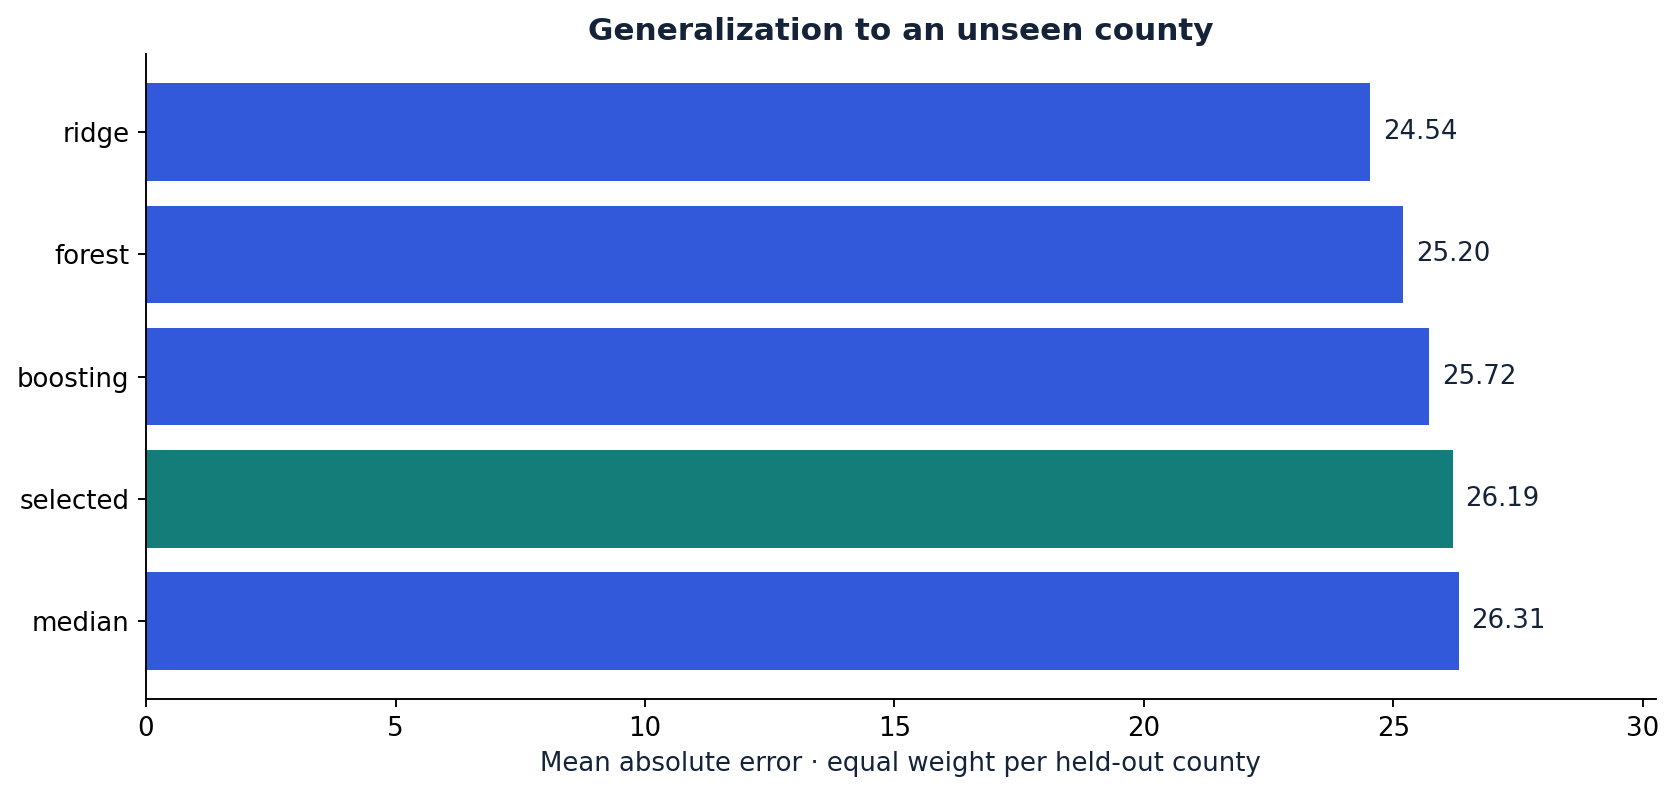

In [4]:
# Full reproducibility command from the VS Code terminal:
# python -m bayair.cli train
# Or Run and Debug → "BayAir: train + evaluate".
if not (reports / 'leaderboard.csv').exists():
    from bayair.experiment import run
    run()
run_info = json.loads((reports / 'run.json').read_text())
assert run_info['data_sha256'] == audit['sha256'], 'Reports belong to a different dataset; rerun training.'
leaderboard = pd.read_csv(reports / 'leaderboard.csv')
display(leaderboard.round(3))
display(Image(filename=str(reports / 'figures' / 'leaderboard.png')))

## 5. Ablations and geographic distribution shift

How much does each feature family add? These scores estimate predictive association, not causal mediation or a treatment effect. The random-split diagnostic uses the same fixed, untuned boosting settings under both schemes; its training-set sizes differ, so its gap is not a pure estimate of spatial leakage.

,feature_set,model,macro_county_mae,county_mae_std,worst_county_mae,pooled_mae,pooled_rmse,pooled_r2
4,air,selected,26.311,19.416,69.072,28.061,42.322,-0.154
9,combined,selected,26.191,11.195,46.842,25.539,36.442,0.145
14,social,selected,24.465,8.959,45.922,23.679,33.595,0.273


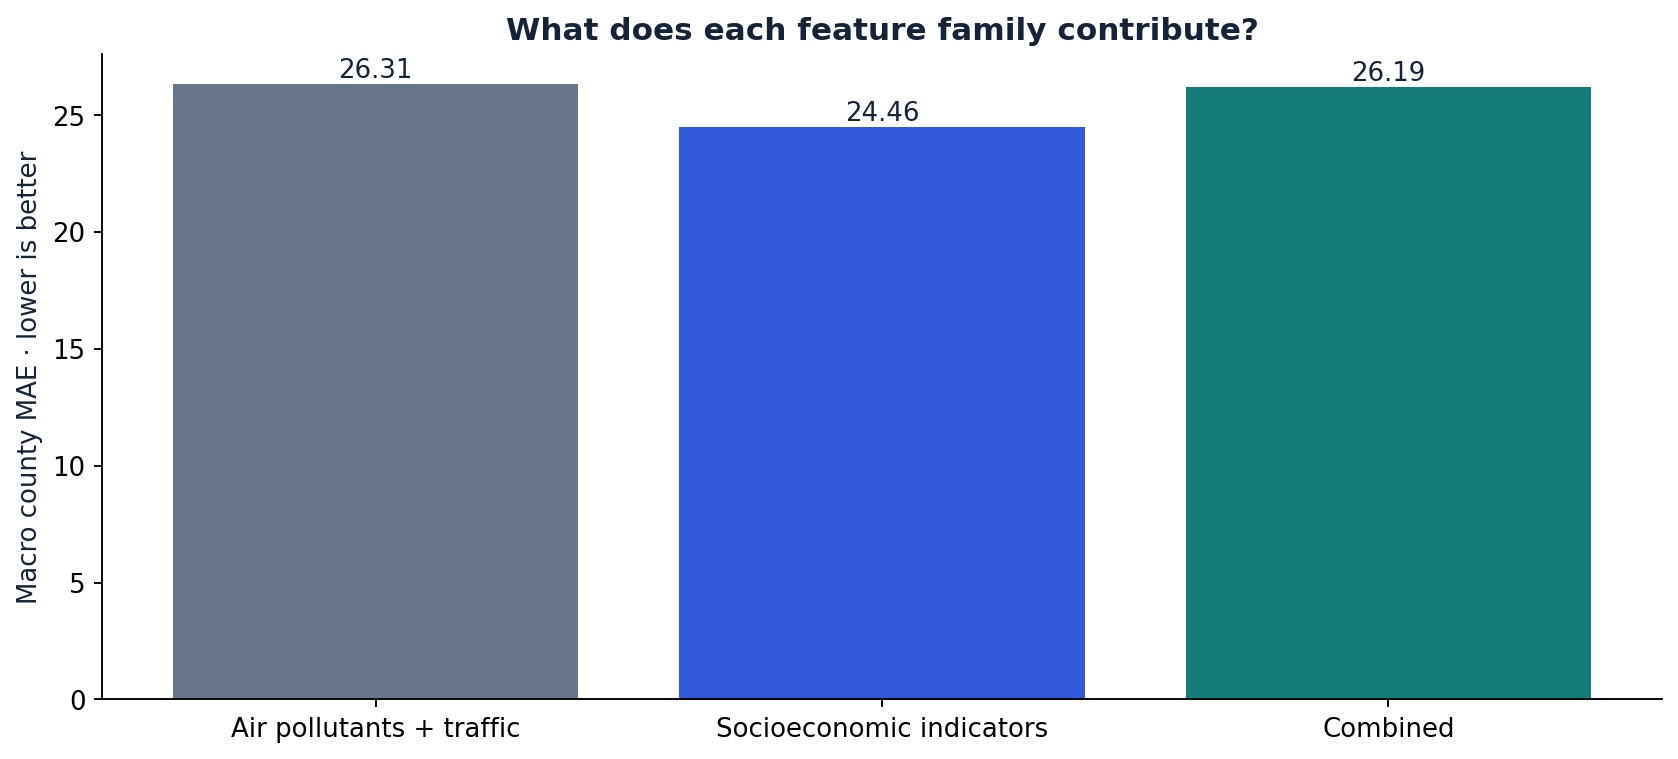

,scheme,mae,rmse,r2
0,random_5fold,18.235,26.945,0.532
1,county_held_out,28.451,38.886,0.026


In [5]:
display(leaderboard.query("model == 'selected'").round(3))
display(Image(filename=str(reports / 'figures' / 'ablation.png')))
display(pd.read_csv(reports / 'split_diagnostic.csv').round(3))

## 6. Failure analysis, before celebrating a headline score

Inspect every county. Positive residuals mean the model underestimates the observed indicator. Error slicing uses a predeclared 40% poverty threshold; it is a diagnostic, not a validated fairness assessment. Some data are missing, and small slices have unstable estimates.

,county,feature_set,model,n_test,inner_mae,best_params,mae,rmse,r2
117,Solano,combined,selected,96,22.415,"{""model__alpha"": 10.0}",46.842,61.322,-0.283
26,Contra Costa,combined,selected,207,28.081,{},38.275,53.445,-0.319
57,Napa,combined,selected,40,25.514,"{""model__alpha"": 10.0}",32.219,42.220,-11.630
12,Alameda,combined,selected,360,24.750,"{""model__alpha"": 0.1}",26.512,37.426,0.281
102,Santa Clara,combined,selected,372,24.737,"{""model__alpha"": 0.1}",22.390,28.838,-1.008
72,San Francisco,combined,selected,195,26.155,"{""model__alpha"": 10.0}",21.546,27.965,-0.180
42,Marin,combined,selected,55,26.413,"{""model__alpha"": 1000.0}",21.449,25.768,-5.539
87,San Mateo,combined,selected,156,24.134,"{""model__alpha"": 0.1}",13.451,17.158,-0.121
132,Sonoma,combined,selected,99,23.635,"{""model__alpha"": 10.0}",13.040,16.258,-0.954


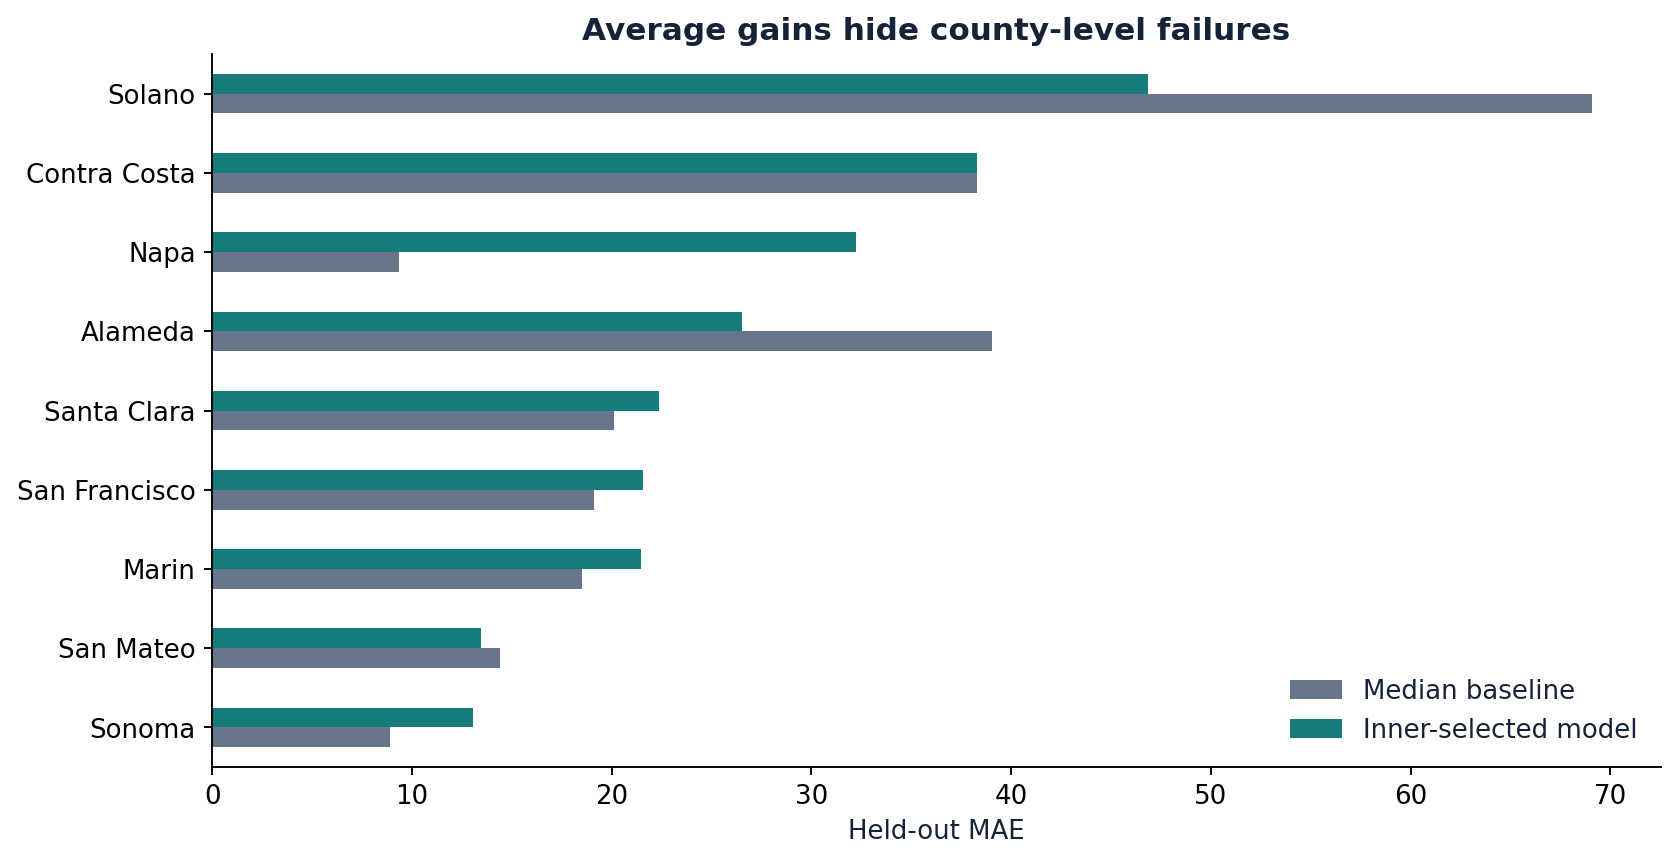

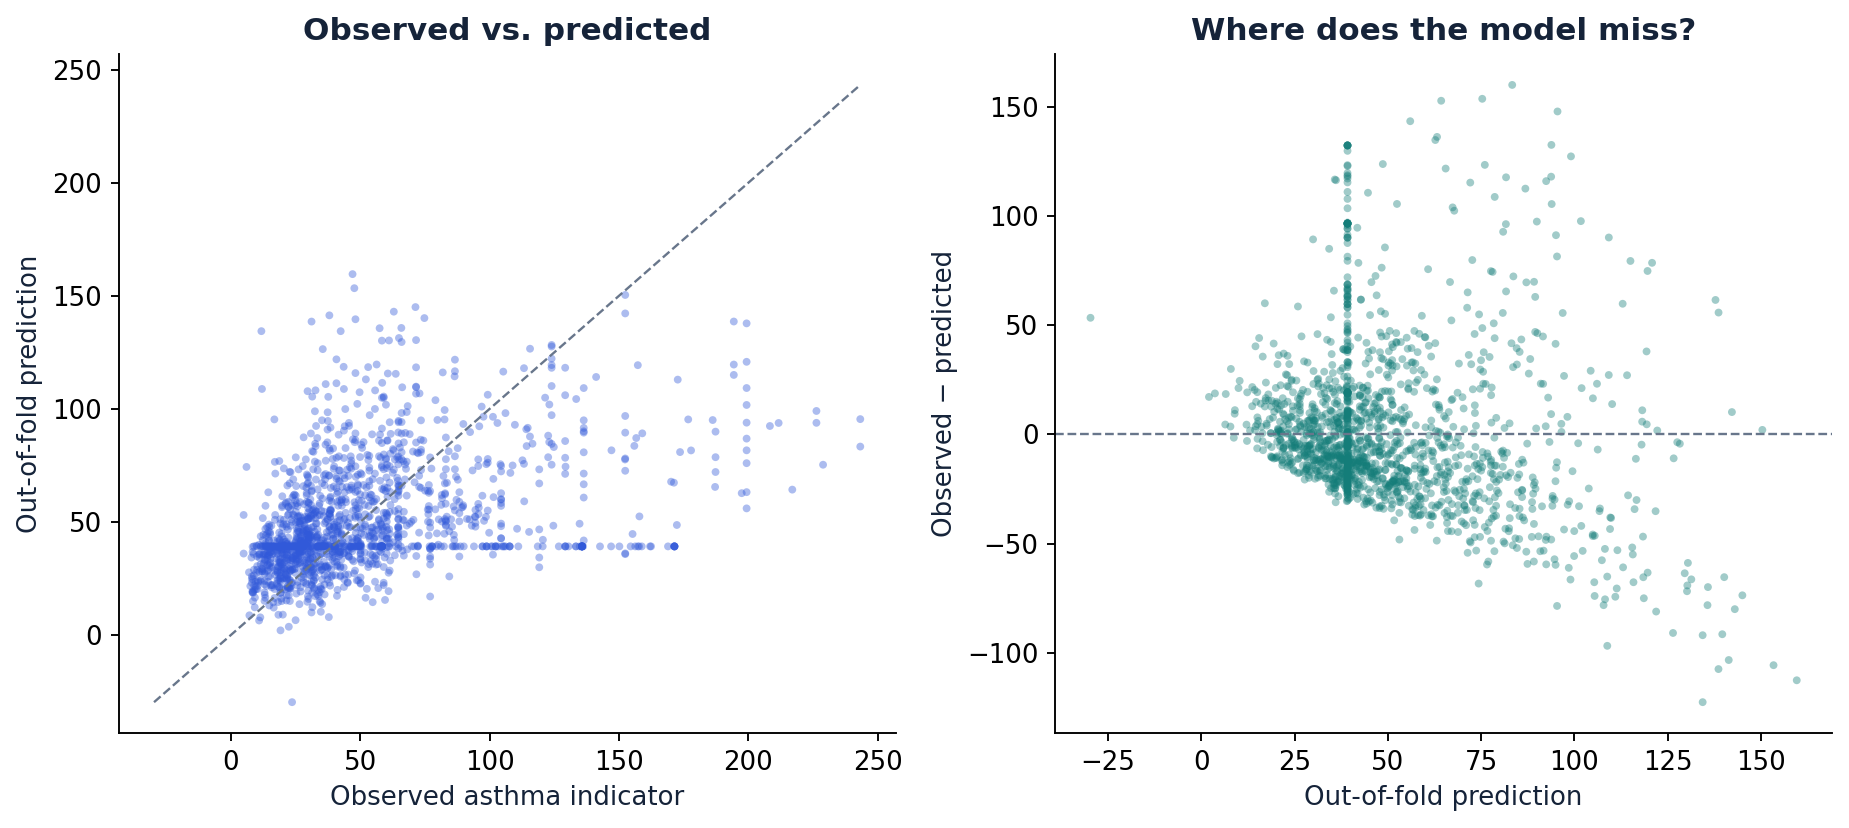

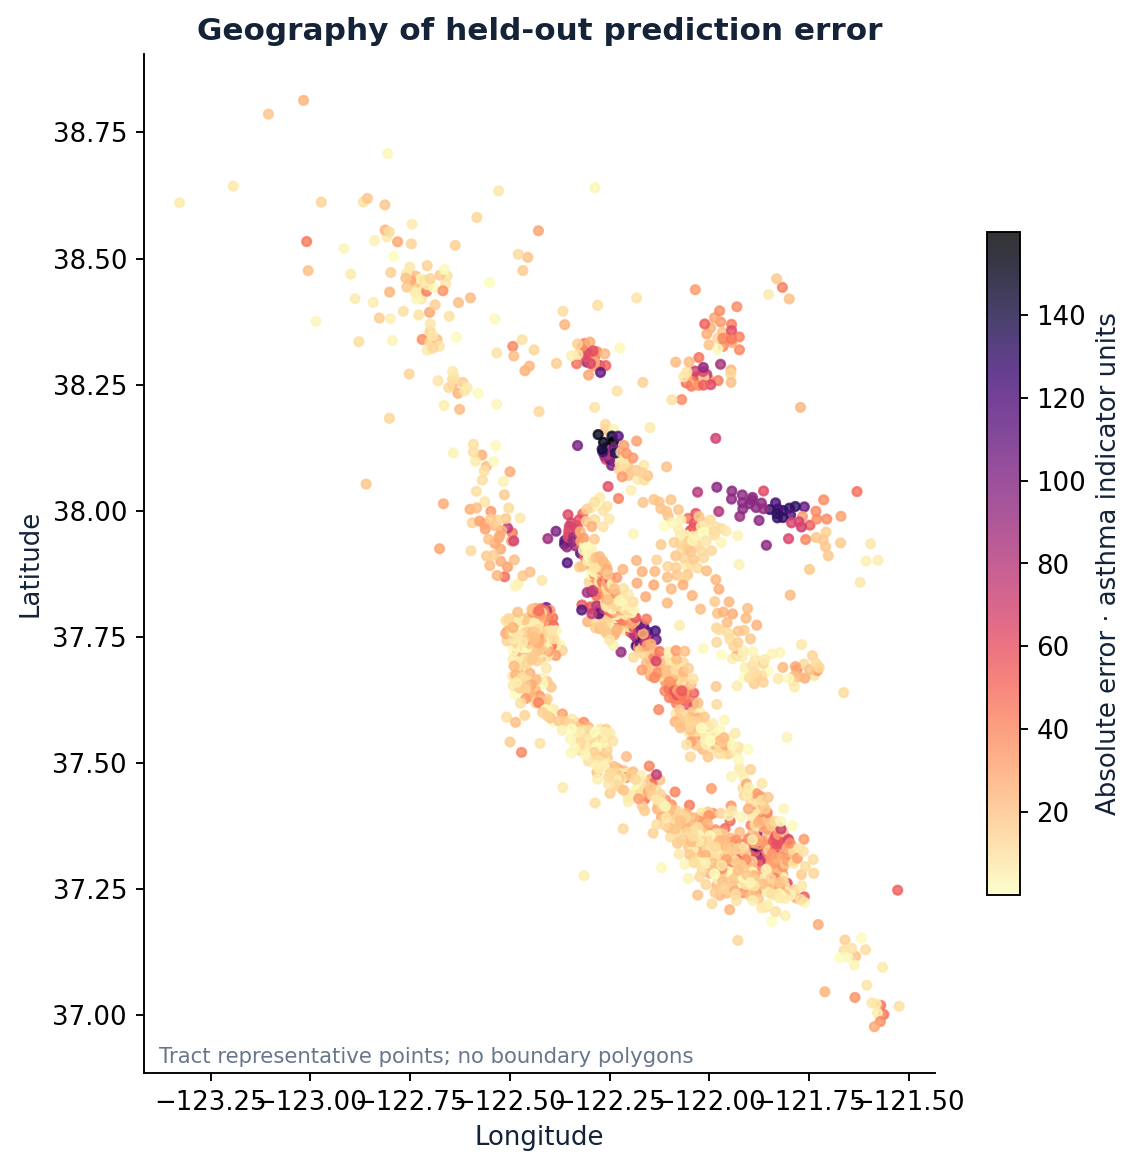

,poverty_slice,n,mae,mean_residual
0,<40%,1379,21.952,-0.471
1,>=40%,193,50.477,12.614
2,missing,8,42.187,10.861


In [6]:
folds = pd.read_csv(reports / 'county_metrics.csv')
display(folds.query("feature_set == 'combined' and model == 'selected'").sort_values('mae', ascending=False).round(3))
display(Image(filename=str(reports / 'figures' / 'county_errors.png')))
display(Image(filename=str(reports / 'figures' / 'residuals.png')))
display(Image(filename=str(reports / 'figures' / 'error_map.png')))
display(pd.read_csv(reports / 'slice_metrics.csv').round(3))

## 7. Interpret held-out predictions

Permutation importance shuffles one feature at a time on the outer test county, using five repeats. The plotted value is the increase in held-out MAE. Correlation between predictors can split or hide predictive reliance. These importances are not causal effects.

A county-resampled bootstrap reports a descriptive stability range for the macro MAE improvement over the baseline. Nine counties and overlapping outer training sets do not support a formal independent-sample confidence interval.

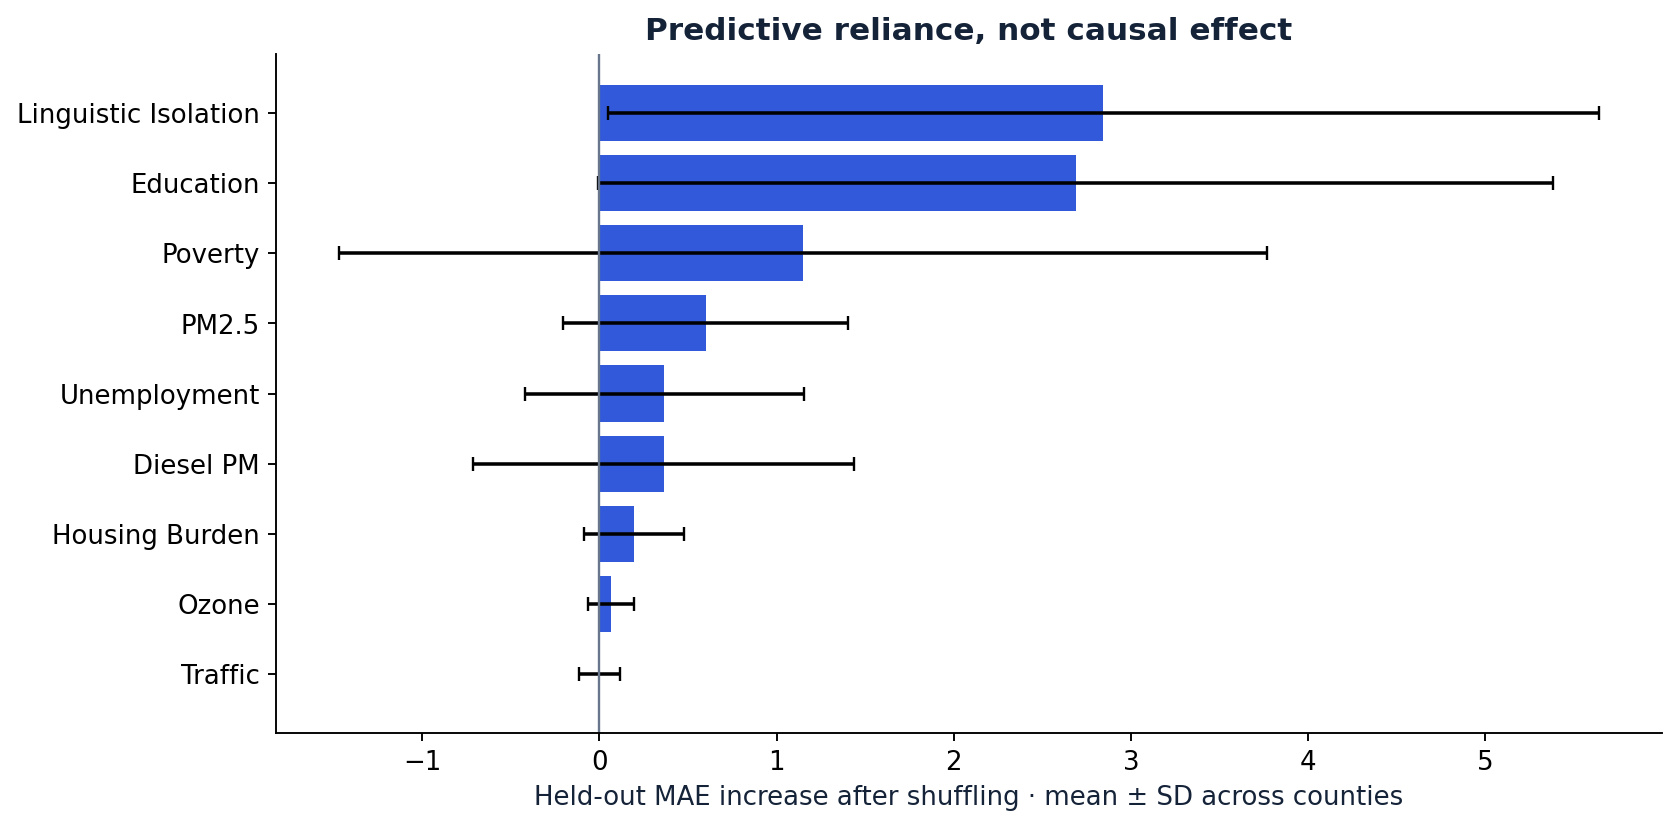

{'macro_mae_improvement': 0.1193749302737369,
 'descriptive_95_percent_range': [-7.500121907514247, 7.736753525878649],
 'counties': 9,
 'repeats': 2000,
 'interpretation': 'County-resampled stability range, not a formal confidence interval; outer training sets overlap.'}

In [7]:
display(Image(filename=str(reports / 'figures' / 'importance.png')))
display(json.loads((reports / 'stability.json').read_text()))

## 8. Reproducibility and what comes next

The training run writes exact split manifests, out-of-fold predictions, feature importance, data audit, runtime versions, and a full-data demonstration model. The offline explorer is `reports/index.html`.

The final full-data model has no fresh independent test set: use the nested out-of-fold procedure scores for reporting. Batch inference supports missing predictors and flags values outside the training range. Range checks do not detect every form of distribution shift.

Next research steps: reconcile the historical extract with its official release; use spatial blocks with explicit distance buffers; examine label smoothing and measurement uncertainty; evaluate genuinely later measurements if longitudinal data become available. Avoid presenting tract-level associations as individual clinical risk or causal pollution effects.

In [8]:
display(run_info)
print((reports / 'RESULTS.md').read_text())

{'seed': 42,
 'python': '3.12.14',
 'packages': {'numpy': '2.3.4',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'matplotlib': '3.10.7',
  'joblib': '1.5.2'},
 'elapsed_seconds': 78.41,
 'primary_metric': 'Unweighted mean of nine held-out county MAEs',
 'outer_folds': 9,
 'inner_folds': 3,
 'data_sha256': 'b60352ee5854698e85ccfbce2bd11209b405d0eb57977e21c65252f358e4420c'}

# Experiment results

Generated from `b60352ee5854698e85ccfbce2bd11209b405d0eb57977e21c65252f358e4420c` using seed 42. See `run.json` for exact versions.

**Primary result:** the inner-selected combined-feature procedure achieves macro county MAE **26.19**, versus **26.31** for the training-median baseline: **0.5%** lower MAE. Pooled out-of-fold R² is **0.145**. Pooled and equal-county metrics weight geography differently.

## Predeclared feature ablation

| Features | Macro county MAE | Pooled R² | Worst county MAE |
|---|---:|---:|---:|
| air | 26.31 | -0.154 | 69.07 |
| social | 24.46 | 0.273 | 45.92 |
| combined | 26.19 | 0.145 | 46.84 |

## Held-out counties (combined, inner-selected)

| County | Tracts | MAE | R² | Selected family |
|---|---:|---:|---:|---|
| Solano | 96 | 46.84 | -0.283 | ridge |
| Contra Costa | 207 | 38.27 | -0.319 | median |
| Napa | 40 | 32.22 | -11.630 | ridge |
| Alameda | 360 | 26.51 | 0.281 | ridge |
| Santa Clara | 372 | 22.39 | -1.008 | ridge |
| San F